# Oil Futures Calendar Spread — OLS Forecasting Study
**Single-file, executable coursework program** · Historical monthly sample through June 2024

**Question:** Can the current WTI futures curve and a small set of lagged economic fundamentals forecast the **next-month change** in the CL2−CL1 spread?

Run cells in order. No online data, no Brent, no external project `.py` modules. The notebook directly reads the `Oil Data.xlsx` file, which contains the four required source columns from the professor-supplied workbook (355 monthly rows). Ensure the `Oil Data.xlsx` file is in the same directory as this notebook before execution.

**Important:** CL1/CL2 are continuous futures series. Price differences and trading P&L below are *proxies*, not verified executable profits. Macro publication delays are assumptions, not validated real-time vintages. The 2019–2024 period has previously been examined; redesigns require a new untouched evaluation period.

**Setup:** Use Python 3.10 or later with `numpy`, `pandas`, `matplotlib`, `statsmodels`, `openpyxl`, `ipykernel` and Jupyter installed. From the notebook's Python environment, run `%pip install numpy pandas matplotlib statsmodels openpyxl ipykernel jupyter` once if needed, then restart the kernel.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey,
    het_breuschpagan,
    het_arch,
    breaks_cusumolsresid,
)

SEED = 20261022

# Agreed two-variable main model and a one-variable OLS comparison
FEATURES = ['spread', 'inventory_growth']
MAIN_MODEL = 'Spread + inventories'
SIMPLE_MODEL = 'Spread only'
OLS_SPECS = {
    SIMPLE_MODEL: ['spread'],
    MAIN_MODEL: FEATURES,
}

VALID_START = pd.Period('2015-01', 'M')
VALID_END = pd.Period('2018-12', 'M')
TEST_START = pd.Period('2019-01', 'M')

In [2]:
# Directly read the only required sheet from the professor's workbook
industry = pd.read_excel('Oil Data.xlsx', sheet_name='Industry_M')
industry.columns = industry.columns.astype(str).str.strip()
industry = industry[['Date', 'CL1', 'CL2', 'Inventories']].copy()

# Convert source dates into calendar-month identifiers
industry['Date'] = pd.to_datetime(industry['Date'], errors='raise')
if industry['Date'].isna().any():
    raise ValueError('The industry worksheet contains missing dates.')
industry['month'] = industry['Date'].dt.to_period('M')
if industry['month'].duplicated().any():
    raise ValueError('The industry worksheet contains duplicate months.')

monthly = industry.set_index('month').sort_index()[['CL1', 'CL2', 'Inventories']]
for column in monthly.columns:
    monthly[column] = pd.to_numeric(monthly[column], errors='raise')
if monthly.isna().any().any():
    raise ValueError('Missing values found in the three selected source columns.')
if not np.isfinite(monthly.to_numpy(float)).all():
    raise ValueError('Non-finite prices/inventories detected.')
if (monthly['Inventories'] <= 0).any():
    raise ValueError('Inventories must be positive for the logarithm.')
if not monthly.index.equals(pd.period_range(monthly.index.min(), monthly.index.max(), freq='M')):
    raise ValueError('There is a gap in the monthly data.')

print(f'Monthly observations: {len(monthly)} | {monthly.index.min()}–{monthly.index.max()}')
display(monthly.head())

Monthly observations: 355 | 1994-12–2024-06


,CL1,CL2,Inventories
month,,,
1994-12,17.76,17.71,904519
1995-01,18.39,18.24,898253
1995-02,18.49,18.35,896939
1995-03,19.17,18.95,912742
1995-04,20.38,20.05,910037


## 1. Import and clean the monthly observations

We read **only** the professor's `Industry_M` worksheet using `pd.read_excel('Oil Data.xlsx', sheet_name='Industry_M')`. The selected source columns are `CL1`, `CL2` and `Inventories`. We remove no valid dates and do not interpolate observations. We convert dates to calendar-month identifiers, check for duplicate or missing months, convert values to numbers, and verify that inventories are positive before calculating logarithms.

The data are already monthly, so there is no need to merge another worksheet or resample a higher-frequency series. Brent and all external numerical data are excluded. Monthly forecasting is more interpretable for this project, although it cannot capture daily trading opportunities.

## 2. Define the target and the two explanatory variables

At month-end \(t\), we aim to forecast **next month's spread change**, not the outright oil price or a percentage oil-price return:

\[
S_t=CL2_t-CL1_t,\quad y_{t+1}=S_{t+1}-S_t.
\]

The model's only two predictors are:

1. **Current spread** \(S_t\), in USD/barrel. It measures the term structure and tests a possible mean-reversion relationship.
2. **Lagged inventory growth** \(IG_{t-2}\), calculated as \(100[\log(I_{t-2})-\log(I_{t-3})]\), in log-percentage points. This is implemented with `.diff().shift(2)` and uses an **assumed two-month availability delay**.

**Why inventories?** The theory of storage relates physical inventory availability to the convenience yield and the commodity futures curve. We test whether lagged inventories add information **beyond the spread itself**; economic relevance does not guarantee incremental forecast accuracy.

We do **not** use previous spread change or industrial-production growth as main predictors. We do **not** z-score the variables; OLS uses the original units above. Correlations and coefficients describe conditional associations, **not causation**. The lag is a conservative assumption, not a verified real-time publication history.

Usable monthly target observations: 351
Pre-2015 estimation observations: 237
Pre-2019 development observations: 285


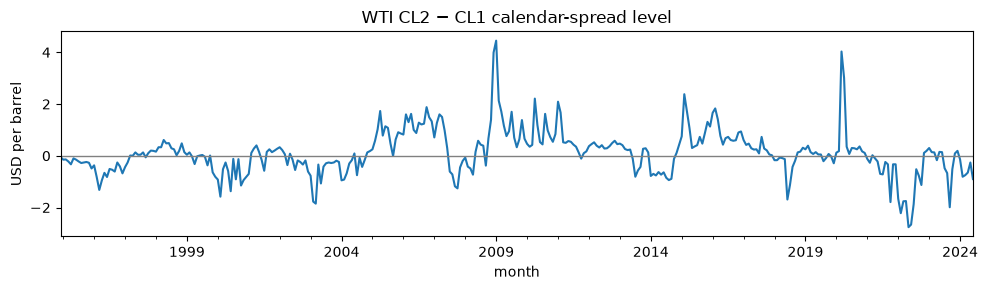

Pre-2015 correlation matrix (association does not imply causality):


,spread,inventory_growth,target
spread,1.000,0.165,-0.303
inventory_growth,0.165,1.000,-0.113
target,-0.303,-0.113,1.000


In [3]:
# Current market spread and lagged physical inventory measure
f = monthly[['CL1', 'CL2']].copy()
f['spread'] = monthly['CL2'] - monthly['CL1']
f['inventory_growth'] = 100 * np.log(monthly['Inventories']).diff().shift(2)

# One-month-ahead dependent variable, in USD per barrel
f['spread_next'] = f['spread'].shift(-1)
f['target'] = f['spread_next'] - f['spread']
f['target_month'] = f.index + 1

# Keep observations with known predictors and an observed later target
frame = f.dropna(subset=FEATURES + ['target', 'spread_next', 'CL1', 'CL2']).copy()
assert (frame['target_month'] == frame.index + 1).all()
assert np.allclose(frame['target'], frame['spread_next'] - frame['spread'])
assert frame.index.equals(pd.period_range(frame.index.min(), frame.index.max(), freq='M'))

# Initial estimation and development periods (historical evaluation comes later)
early = frame[frame['target_month'] < VALID_START].copy()
dev = frame[frame['target_month'] < TEST_START].copy()
assert len(frame) == 351 and len(early) == 237 and len(dev) == 285
assert (frame['target_month'] >= TEST_START).sum() == 66

print('Usable monthly target observations:', len(frame))
print('Pre-2015 estimation observations:', len(early))
print('Pre-2019 development observations:', len(dev))

fig, ax = plt.subplots(figsize=(10, 3))
f['spread'].plot(ax=ax)
ax.axhline(0, color='grey', lw=1)
ax.set(title='WTI CL2 − CL1 calendar-spread level', ylabel='USD per barrel')
plt.tight_layout()
plt.show()

# Correlation screening is deliberately restricted to the earliest sample.
print('Pre-2015 correlation matrix (association does not imply causality):')
display(early[FEATURES + ['target']].corr().round(3))

## 3. OLS and chronological one-month-ahead forecasts

Our **main model is fixed in advance for this notebook** as `Spread + inventories`. `Spread only` is the simpler nested OLS comparison, not a different chosen main model. Each OLS includes an intercept and is re-estimated on an expanding historical window.

For each forecast origin \(t\), the estimation sample contains only earlier forecast origins whose targets are already known by \(t\). The 2015–2018 months serve as chronological **validation**. We also calculate two simple benchmarks: **zero spread change** and the **expanding historical mean**. We compare forecast errors and do not automatically choose a new specification from validation or the later historical evaluation period.

In [4]:
def predict_ols(train, current, predictors):
    X = sm.add_constant(train[predictors], has_constant='add')
    fitted = sm.OLS(train['target'], X).fit()
    new = sm.add_constant(pd.DataFrame([current[predictors]]), has_constant='add')
    return float(fitted.predict(new).iloc[0])

def rolling_predictions(frame, model, periods, window=None):
    forecasts = []
    for origin in periods:
        pos = frame.index.get_loc(origin)
        start = max(0, pos - window) if window is not None else 0
        train = frame.iloc[start:pos]
        assert len(train) >= 60
        assert train['target_month'].max() <= origin, 'Future target leaked into estimation'
        current = frame.loc[origin]
        if model in OLS_SPECS:
            predicted = predict_ols(train, current, OLS_SPECS[model])
        elif model == 'Zero change':
            predicted = 0.0
        elif model == 'Expanding mean':
            predicted = float(train['target'].mean())
        else:
            raise ValueError(f'Unknown model: {model}')
        forecasts.append({
            'model': model, 'origin': str(origin), 'target_month': str(origin + 1),
            'actual': float(current['target']), 'prediction': predicted,
            'spread': float(current['spread']), 'CL1': float(current['CL1']),
            'CL2': float(current['CL2']),
        })
    return pd.DataFrame(forecasts)

def score(panel):
    error = panel['actual'] - panel['prediction']
    return {
        'n': len(error),
        'RMSE': float(np.sqrt(np.mean(error**2))),
        'MAE': float(np.mean(np.abs(error))),
        'MSE': float(np.mean(error**2)),
    }

MODEL_ORDER = [MAIN_MODEL, SIMPLE_MODEL, 'Zero change', 'Expanding mean']
validation_periods = frame.index[
    (frame['target_month'] >= VALID_START) & (frame['target_month'] <= VALID_END)
]
validation = {name: rolling_predictions(frame, name, validation_periods)
              for name in MODEL_ORDER}
valid_scores = pd.DataFrame({name: score(panel) for name, panel in validation.items()}).T
valid_scores['OOS R² vs zero (%)'] = 100 * (1 - valid_scores['MSE'] /
                                             valid_scores.loc['Zero change', 'MSE'])
print('Validation: Jan 2015–Dec 2018, 48 one-month-ahead forecasts')
display(valid_scores[['n', 'RMSE', 'MAE', 'OOS R² vs zero (%)']].round(5))

# Fixed main specification; do not change it using the later historical evaluation.
selected_ols = MAIN_MODEL
print('Chosen main specification:', selected_ols)

Validation: Jan 2015–Dec 2018, 48 one-month-ahead forecasts


,n,RMSE,MAE,OOS R² vs zero (%)
Spread + inventories,48.0,0.44034,0.28337,9.44946
Spread only,48.0,0.44185,0.28112,8.82838
Zero change,48.0,0.46275,0.31000,0.00000
Expanding mean,48.0,0.46367,0.31072,-0.39962


Chosen main specification: Spread + inventories


## 4. In-sample fit and information criteria

Using the **same pre-2015 observations** for both OLS regressions, report **\(R^2\)**, **adjusted \(R^2\)**, **AIC** and **BIC**. \(R^2\) cannot fall when we add a regressor to a nested standard OLS model, so it should not determine the model by itself. Adjusted \(R^2\), AIC and BIC penalise complexity in different ways. **Lower AIC and BIC is preferable.**

The coursework prioritises **forecasting later observations**, so in-sample criteria are complemented by chronological RMSE, MAE and naïve benchmarks. No ARMA model is fitted here: our comparison remains focused on one- and two-variable OLS.

Pre-2015 fit and information criteria:


,n,R²,Adjusted R²,AIC,BIC
Spread only,237.0,0.09189,0.08802,323.00352,329.93964
Spread + inventories,237.0,0.09596,0.08823,323.93801,334.34219


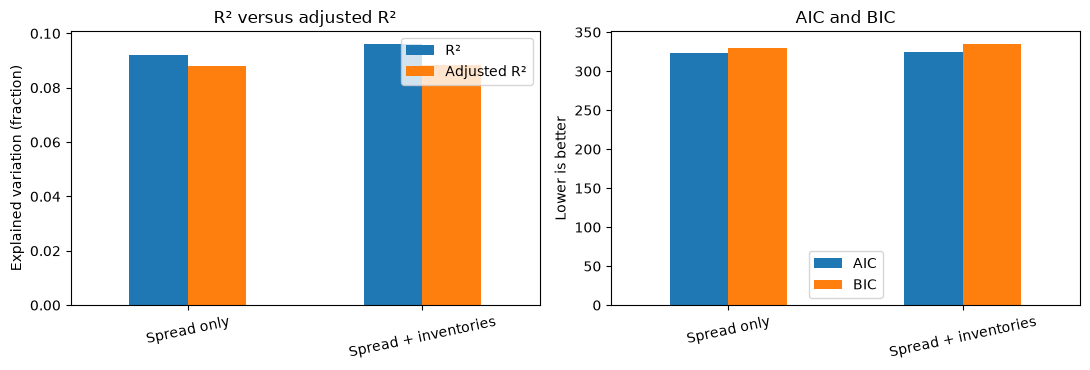

In [5]:
# Both OLS models must be estimated using exactly the same pre-2015 data.
fit_results = {}
for name, predictors in OLS_SPECS.items():
    X = sm.add_constant(early[predictors], has_constant='add')
    fit_results[name] = sm.OLS(early['target'], X).fit()

fit_table = pd.DataFrame({
    name: {
        'n': int(fitted.nobs), 'R²': fitted.rsquared,
        'Adjusted R²': fitted.rsquared_adj,
        'AIC': fitted.aic, 'BIC': fitted.bic,
    }
    for name, fitted in fit_results.items()
}).T
print('Pre-2015 fit and information criteria:')
display(fit_table.round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
fit_table[['R²', 'Adjusted R²']].plot.bar(ax=axes[0], rot=0)
axes[0].set(title='R² versus adjusted R²', ylabel='Explained variation (fraction)')
fit_table[['AIC', 'BIC']].plot.bar(ax=axes[1], rot=0)
axes[1].set(title='AIC and BIC', ylabel='Lower is better')
for ax in axes:
    ax.tick_params(axis='x', labelrotation=12)
plt.tight_layout()
plt.show()

## 5. Historical forecast evaluation against naïve benchmarks

For **January 2019–June 2024**, calculate 66 expanding-window one-month-ahead forecasts for the two OLS specifications and the two naïve benchmarks, always using the **same forecast months**.

We report **RMSE**, **MAE**, **MSE improvement over zero change**, and **directional accuracy** (for nonzero directional forecasts). RMSE penalises large errors more heavily; MAE measures the average absolute error. The MSE-improvement percentage is \(100\times[1-MSE_{model}/MSE_{zero}]\). Positive is better than the zero-change benchmark; negative is worse.

**Important:** We previously inspected this historical evaluation period during model exploration. It remains useful descriptively but is **not a fresh untouched holdout** for selecting the revised two-variable model. Smaller forecasting error also does not, by itself, establish an executable trading profit.

Historical evaluation: Jan 2019–Jun 2024 (previously examined period)


,n,RMSE,MAE,MSE improvement vs zero (%),Directional accuracy (%)
Spread + inventories,66.0,0.7536,0.4507,10.9298,53.0303
Spread only,66.0,0.7538,0.4399,10.8754,57.5758
Zero change,66.0,0.7985,0.4598,0.0000,NaN
Expanding mean,66.0,0.7998,0.4610,-0.3199,34.8485


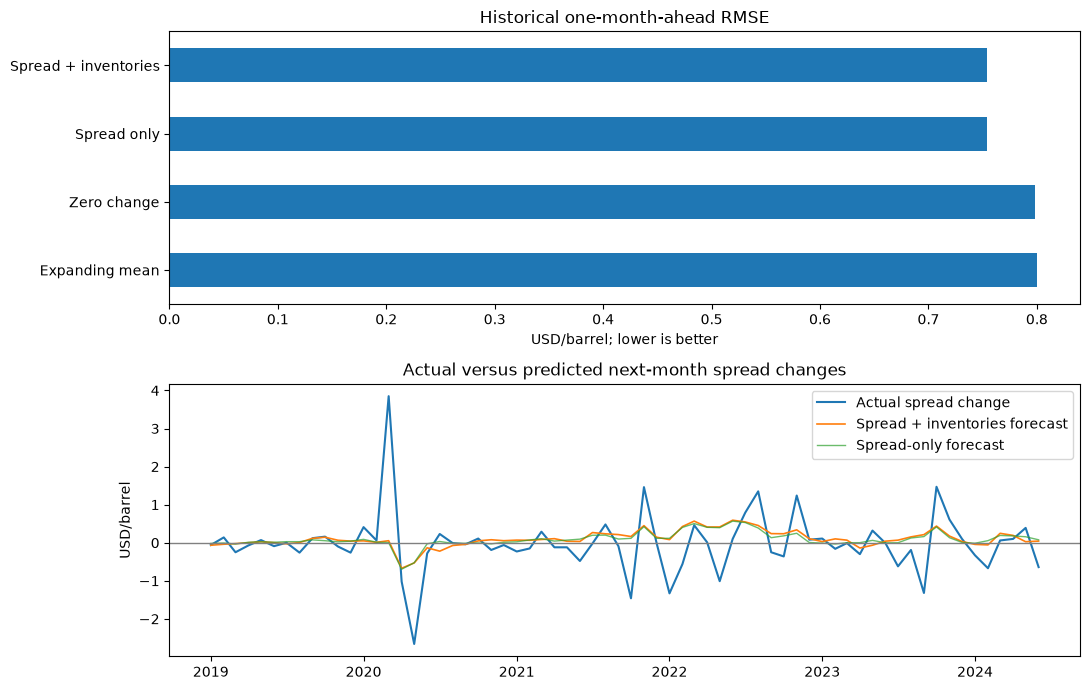

In [6]:
# All four forecasting approaches are evaluated on the same 66 target months.
test_periods = frame.index[frame['target_month'] >= TEST_START]
test_panels = {name: rolling_predictions(frame, name, test_periods)
               for name in MODEL_ORDER}
for name, panel in test_panels.items():
    assert panel['target_month'].equals(test_panels[MAIN_MODEL]['target_month'])
    assert np.allclose(panel['actual'], test_panels[MAIN_MODEL]['actual'])

def directional_accuracy(panel):
    actual = panel['actual'].to_numpy(float)
    predicted = panel['prediction'].to_numpy(float)
    if np.all(predicted == 0):
        return np.nan  # The zero-change benchmark never predicts a direction.
    return float(100 * np.mean(np.sign(actual) == np.sign(predicted)))

base_mse = score(test_panels['Zero change'])['MSE']
results = pd.DataFrame({
    name: {
        **score(panel),
        'MSE improvement vs zero (%)': 100 * (1 - score(panel)['MSE'] / base_mse),
        'Directional accuracy (%)': directional_accuracy(panel),
    }
    for name, panel in test_panels.items()
}).T
print('Historical evaluation: Jan 2019–Jun 2024 (previously examined period)')
display(results[['n', 'RMSE', 'MAE', 'MSE improvement vs zero (%)',
                 'Directional accuracy (%)']].round(4))
assert len(test_panels[MAIN_MODEL]) == 66

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
results['RMSE'].sort_values().plot(kind='barh', ax=axes[0])
axes[0].invert_yaxis()
axes[0].set(title='Historical one-month-ahead RMSE', xlabel='USD/barrel; lower is better')

forecast = test_panels[MAIN_MODEL].sort_values('target_month')
dates = pd.PeriodIndex(forecast['target_month'], freq='M').to_timestamp()
axes[1].plot(dates, forecast['actual'], label='Actual spread change', linewidth=1.5)
axes[1].plot(dates, forecast['prediction'], label='Spread + inventories forecast', linewidth=1.2)
axes[1].plot(dates, test_panels[SIMPLE_MODEL]['prediction'],
             label='Spread-only forecast', linewidth=1, alpha=.7)
axes[1].axhline(0, color='grey', lw=1)
axes[1].set(title='Actual versus predicted next-month spread changes', ylabel='USD/barrel')
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Interpret the main OLS and check its assumptions

Estimate **spread + inventories** on pre-2019 development observations for interpretable coefficients; the forecasting procedure above re-estimates using the available history at every origin. HAC (Newey–West) standard errors allow for short-run residual autocorrelation and heteroskedasticity when assessing coefficient uncertainty. They do **not** repair misspecification, prove causality or improve the forecasts.

Check the regression residuals with **Breusch–Godfrey** (autocorrelation), **Breusch–Pagan** (heteroskedasticity), **ARCH LM** (conditional volatility) and **CUSUM** (stability), and inspect residual and Q–Q plots. Use **ADF** and **KPSS** on the spread, lagged inventory growth and target to assess stationarity: ADF's null is a **unit root**, KPSS's null is **stationarity**. A negative spread coefficient may be consistent with mean reversion, but the target contains a subtraction of the current spread, so interpretation should be cautious.

Interpret the actual printed test results rather than carrying forward p-values from the old OLS4 model.

,coefficient,HAC SE,HAC p-value
const,0.03862,0.02647,0.14557
spread,-0.17622,0.03457,0.00000
inventory_growth,-0.03169,0.02394,0.18661


,p-value
Breusch–Godfrey p (12),0.75947
Breusch–Pagan p,0.01812
ARCH LM p (6),0.00318
CUSUM p,0.08183
ADF target p,0.00000
KPSS target p,0.10000


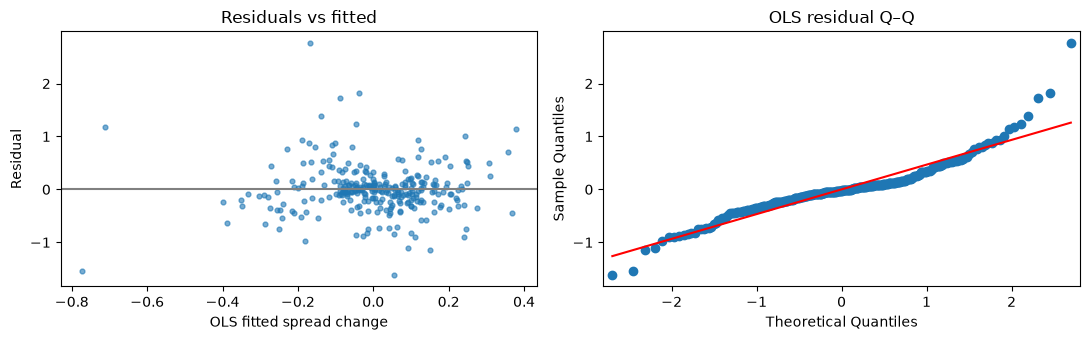

Interpret coefficients as conditional associations, not causal effects.
Development-sample stationarity checks: ADF null = unit root; KPSS null = stationarity.


/var/folders/gc/7fy0cgq57j78bfsgtnwlzvgw0000gn/T/ipykernel_64547/2875269702.py:29: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result=adfuller(series,maxlag=12,regression='c',autolag='AIC')
/var/folders/gc/7fy0cgq57j78bfsgtnwlzvgw0000gn/T/ipykernel_64547/2875269702.py:29: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result=adfuller(series,maxlag=12,regression='

,n,ADF p-value,KPSS p-value,assessment (5%),KPSS note
variable,,,,,
spread,285,0.00000,0.02198,Mixed or inconclusive evidence,
inventory_growth,285,0.04999,0.10000,Evidence consistent with stationarity,The test statistic is outside of the range of ...
target,285,0.00000,0.10000,Evidence consistent with stationarity,The test statistic is outside of the range of ...


KPSS boundary p-values are bounds from the tabulated distribution, not exact probabilities.


In [7]:
cols=OLS_SPECS[selected_ols]
X=sm.add_constant(dev[cols],has_constant='add')
ols=sm.OLS(dev.target,X).fit()
robust=ols.get_robustcov_results(cov_type='HAC',maxlags=6)
coef=pd.DataFrame({'coefficient':robust.params,'HAC SE':robust.bse,'HAC p-value':robust.pvalues},index=X.columns)
display(coef.round(5))
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    diagnostics={
        'Breusch–Godfrey p (12)':acorr_breusch_godfrey(ols,nlags=12)[1],
        'Breusch–Pagan p':het_breuschpagan(ols.resid,ols.model.exog)[1],
        'ARCH LM p (6)':het_arch(ols.resid,nlags=6)[1],
        'CUSUM p':breaks_cusumolsresid(ols.resid,ddof=int(ols.df_model)+1)[1],
        'ADF target p':adfuller(dev.target,maxlag=12,autolag='AIC')[1],
        'KPSS target p':kpss(dev.target,nlags='auto')[1],
    }
display(pd.Series(diagnostics,name='p-value').to_frame().round(5))
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].scatter(ols.fittedvalues,ols.resid,s=12,alpha=.6);axes[0].axhline(0,color='grey');axes[0].set(xlabel='OLS fitted spread change',ylabel='Residual',title='Residuals vs fitted')
sm.qqplot(ols.resid,line='s',ax=axes[1]);axes[1].set(title='OLS residual Q–Q')
plt.tight_layout();plt.show()
print('Interpret coefficients as conditional associations, not causal effects.')
from statsmodels.tools.sm_exceptions import InterpolationWarning

# Apply the same stationarity checks to every predictor and the dependent variable.
stationarity_rows=[]
for variable in FEATURES+['target']:
    series=dev[variable].dropna()
    adf_result=adfuller(series,maxlag=12,regression='c',autolag='AIC')
    with warnings.catch_warnings(record=True) as recorded:
        warnings.simplefilter('always')
        kpss_result=kpss(series,regression='c',nlags='auto')
    adf_p,kpss_p=adf_result[1],kpss_result[1]
    if adf_p<0.05 and kpss_p>=0.05:
        conclusion='Evidence consistent with stationarity'
    elif adf_p>=0.05 and kpss_p<0.05:
        conclusion='Evidence against stationarity'
    else:
        conclusion='Mixed or inconclusive evidence'
    stationarity_rows.append({'variable':variable,'n':len(series),
        'ADF p-value':adf_p,'KPSS p-value':kpss_p,
        'assessment (5%)':conclusion,
        'KPSS note':'; '.join(str(w.message) for w in recorded if issubclass(w.category, InterpolationWarning))})
stationarity=pd.DataFrame(stationarity_rows).set_index('variable')
print('Development-sample stationarity checks: ADF null = unit root; KPSS null = stationarity.')
display(stationarity.round(5))
print('KPSS boundary p-values are bounds from the tabulated distribution, not exact probabilities.')


## 7. How much does inventories improve forecasting accuracy?

Using the **existing chronological forecasts**, compare the two-variable model directly against **spread-only OLS on the 2015–2018 validation period**. Also compare the two-variable model to **zero change** in validation and in historical evaluation.

We summarise the difference in average **squared forecast losses** with an illustrative paired six-month moving-block bootstrap interval. **Positive mean benefit** indicates smaller squared loss for the two-variable model. An interval including zero means no clear improvement is demonstrated. These intervals do not adjust for all prior experimentation or structural changes.

In [8]:
def bootstrap_benefit(reference, candidate, seed=SEED, block=6, reps=2000):
    assert reference['target_month'].tolist() == candidate['target_month'].tolist()
    actual = reference['actual'].to_numpy(float)
    assert np.allclose(actual, candidate['actual'].to_numpy(float))

    loss_reference = (actual - reference['prediction'].to_numpy(float))**2
    loss_candidate = (actual - candidate['prediction'].to_numpy(float))**2
    difference = loss_reference - loss_candidate  # Positive favours candidate.
    n = len(difference)
    rng = np.random.default_rng(seed)
    bootstrap_means = np.empty(reps)

    for j in range(reps):
        starts = rng.integers(0, n, size=int(np.ceil(n / block)))
        indices = np.concatenate([(s + np.arange(block)) % n for s in starts])[:n]
        bootstrap_means[j] = difference[indices].mean()

    low, high = np.quantile(bootstrap_means, [0.025, 0.975])
    return {
        'Mean MSE benefit': difference.mean(),
        '95% lower': low, '95% upper': high,
        '95% interval includes zero': bool(low <= 0 <= high),
    }

bootstrap_table = pd.DataFrame({
    'Inventories vs spread only — validation': bootstrap_benefit(
        validation[SIMPLE_MODEL], validation[MAIN_MODEL]),
    'Main vs zero — validation': bootstrap_benefit(
        validation['Zero change'], validation[MAIN_MODEL], seed=SEED + 1),
    'Main vs zero — evaluation': bootstrap_benefit(
        test_panels['Zero change'], test_panels[MAIN_MODEL], seed=SEED + 2),
}).T
print('Squared-loss benefit in (USD/barrel)²; positive favours the second model:')
display(bootstrap_table.round(5))

Squared-loss benefit in (USD/barrel)²; positive favours the second model:


,Mean MSE benefit,95% lower,95% upper,95% interval includes zero
Inventories vs spread only — validation,0.00133,-0.004923,0.008187,True
Main vs zero — validation,0.020234,-0.012939,0.056021,True
Main vs zero — evaluation,0.069687,-0.0286,0.195053,True


## 8. Trading decision illustration **versus baselines**
**Important limitation:** The following is a *continuous-spread change proxy*, **not verified futures P&L**. The project lacks contract IDs, roll timing, executable bid/ask quotes, margin and collateral returns. If predicted spread change exceeds +$0.10, the illustration is long CL2/short CL1; below −$0.10, the opposite; otherwise flat. Each active month is a newly entered and closed two-leg position, so four one-way transactions are charged. We compare the selected OLS signal, an always-long-spread baseline, and flat exposure. Graphs start at 100 solely for visual comparison, not as investable wealth indices.

,total_proxy_usd_per_bbl,active_months
strategy,,
Always flat,0.00,0
Always long spread,-7.81,66
Spread + inventories,3.78,32


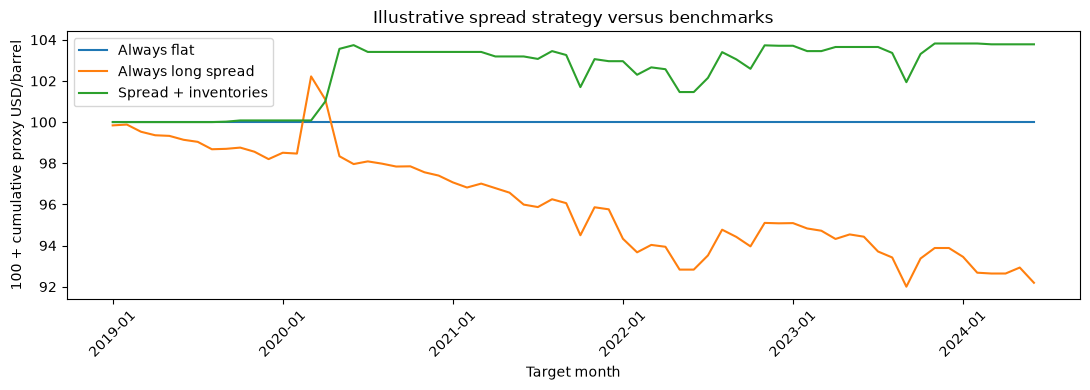

CAUTION: baseline and OLS are proxy spread-change payoffs, not investable total returns.


In [9]:
COST_LEG_WAY=0.025  # USD per barrel per leg per one-way transaction; assumption, not observed cost
BAND=0.10
p=test_panels[selected_ols].copy().sort_values('target_month')
actual=p.actual.to_numpy(float)
def proxy_path(signal,name,cost=COST_LEG_WAY):
    q=np.where(signal>BAND,1,np.where(signal< -BAND,-1,0))
    gross=q*actual
    costs=4*cost*(q!=0)
    net=gross-costs
    return pd.DataFrame({'month':p.target_month,'strategy':name,'position':q,'net':net,'cum_dollars':np.cumsum(net),'index_100':100+np.cumsum(net)})
long_short=proxy_path(p.prediction.to_numpy(float),selected_ols)
always_long=proxy_path(np.full(len(p),np.inf),'Always long spread')
flat=proxy_path(np.zeros(len(p)),'Always flat')
trading=pd.concat([long_short,always_long,flat],ignore_index=True)
trading_summary=trading.groupby('strategy').agg(total_proxy_usd_per_bbl=('net','sum'),active_months=('position',lambda q:int((q!=0).sum())))
display(trading_summary.round(3))
fig,ax=plt.subplots(figsize=(11,4))
for name,grp in trading.groupby('strategy'):
    ax.plot(grp['month'].astype(str),grp['index_100'],label=name)
ax.set(title='Illustrative spread strategy versus benchmarks',ylabel='100 + cumulative proxy USD/barrel',xlabel='Target month')
ax.set_xticks(range(0,len(p),12));ax.legend();plt.xticks(rotation=45);plt.tight_layout();plt.show()
print('CAUTION: baseline and OLS are proxy spread-change payoffs, not investable total returns.')

## 9. Focused robustness checks

Keep **spread + inventories** as the main model. Compare the default expanding training sample with a **120-month rolling estimation window**, and compare the assumed two-month inventory availability delay against a **three-month delay**. These sensitivity analyses do **not** reselect the preferred specification after observing the historical evaluation results. Publication timing and revisions remain limitations.

In [10]:
rolling120 = rolling_predictions(frame, MAIN_MODEL, test_periods, window=120)
print('Main model, expanding window:', score(test_panels[MAIN_MODEL]))
print('Main model, rolling 120-month window:', score(rolling120))

# Rebuild inventory growth with a longer assumed delay; no macro variables.
lag3 = f.copy()
lag3['inventory_growth'] = 100 * np.log(monthly['Inventories']).diff().shift(3)
lag3 = lag3.dropna(subset=FEATURES + ['target', 'spread_next', 'CL1', 'CL2']).copy()
lag3_test = lag3.index[lag3['target_month'] >= TEST_START]
lag3_pred = rolling_predictions(lag3, MAIN_MODEL, lag3_test)
assert lag3_pred['target_month'].tolist() == test_panels[MAIN_MODEL]['target_month'].tolist()
print('Main model, 3-month inventory delay:', score(lag3_pred))
print('These are sensitivity checks, not results used to reselect the main model.')

Main model, expanding window: {'n': 66, 'RMSE': 0.7535927007744287, 'MAE': 0.45068201117853063, 'MSE': 0.5679019586604976}
Main model, rolling 120-month window: {'n': 66, 'RMSE': 0.7551359507630689, 'MAE': 0.46085848818108194, 'MSE': 0.5702303041348441}
Main model, 3-month inventory delay: {'n': 66, 'RMSE': 0.7570667483683687, 'MAE': 0.44715273386247806, 'MSE': 0.5731500614850549}
These are sensitivity checks, not results used to reselect the main model.


## 10. Interpretation and presentation defence

**What we did.** We forecast monthly changes in the WTI **CL2−CL1** calendar spread. We used one main OLS regression with **two explanatory variables**, current spread and two-month-lagged inventory log growth, and compared it against **spread-only OLS**, **zero change** and an **expanding mean**. No industrial production, previous spread change, Brent or external numerical data entered the final main equation.

**Why these two predictors?** The spread captures current futures-market conditions and tests the possibility of adjustment or mean reversion. Inventories provide a physical-market fundamental motivated by the theory of storage. Our question is **whether past inventories provide additional predictive information once the spread is already known**. We cannot infer causation from the regression.

**Model fit versus forecasting performance.** Ordinary \(R^2\) mechanically increases in a nested regression as predictors are added, so we also report adjusted \(R^2\), AIC, BIC, coefficient uncertainty, chronological RMSE/MAE and performance against naïve benchmarks. The pre-2015 comparison slightly favours the two-variable model on adjusted \(R^2\), but AIC and BIC prefer spread only. The choice to retain inventories is **economically motivated**, not a claim that every statistical criterion favours it.

**Forecast accuracy (approximately, USD/barrel).** During 2015–2018 validation, the two-variable RMSE is **0.44034** versus **0.44185** for spread only. During 2019–June 2024 historical evaluation, RMSE is **0.75359** versus **0.75382** for spread only. However, spread-only performs better on later evaluation MAE (**0.43990** versus **0.45068**). The inventory contribution is **very small**; it would be wrong to claim proven superior predictability.

**Uncertainty and diagnostics.** Refer to the newly executed coefficient and diagnostic tables in Sections 6–7. HAC standard errors improve inference under certain disturbances but do not address all possible misspecification. Heteroskedasticity/ARCH, structural changes, mixed stationarity evidence and unverified historical availability of inventory data remain relevant caveats. A bootstrap interval that contains zero does not establish a reliable forecasting gain.

**Trader interpretation.** Forecasts may inform scenarios for widening or narrowing calendar spreads. However, generic monthly CL1 and CL2 series change contract identity with futures rolls. The model's hypothetical payoff proxy is **not verified executable profits or percentage investment returns**; execution prices, rolls, bid–ask spreads, liquidity and collateral are not reconstructed.

**Historical evaluation caveat.** The 2019–2024 period was already examined during the project and is not a freshly untouched test of this revised specification. We should describe this transparently rather than claim unbiased post-selection confirmation.

**Submission.** This is one executable Jupyter program. The coursework still separately requires a 2,000-word report and five-minute presentation. Before handing in, run **Kernel → Restart & Run All** and save outputs so the code, charts and written interpretation are consistent.